In [3]:
import pandas as pd
df=pd.read_csv("Final_Cleaned_Data.csv")

In [18]:
#Day 20

#df.info()
Total_revenue=df["Sales"].sum()
Total_orders=df["Order_ID"].nunique()

AOV=Total_revenue/Total_orders

Total_Units_Sold=df["Quantity"].sum()

print("Total Revenue:", Total_revenue)
print("Total Orders:", Total_orders)
print("Average Order Value:", AOV)
print("Total Units Sold:", Total_Units_Sold)

product_revenue=df.groupby("Product_Name")["Sales"].sum()
product_revenue=product_revenue.sort_values(ascending=False)
print(product_revenue)

category_revenue = df.groupby("Category")["Sales"].sum()
category_revenue = category_revenue.sort_values(ascending=False)
print(category_revenue)

df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.month_name()
df["Quarter"] = df["Order_Date"].dt.quarter
df["Year_Month"] = df["Order_Date"].dt.to_period("M")

Total Revenue: 1021331.5999999999
Total Orders: 3350
Average Order Value: 304.8751044776119
Total Units Sold: 12300.0
Product_Name
School Bag                      164645.00
A4 Copier Paper - 500 Sheets     72912.00
Calculator                       70412.50
Lunch Box                        54593.00
Poster Colour Set                51552.00
Fountain Pen                     40806.00
Water Bottle                     37827.00
Desk Organizer                   35976.50
Water Colour Set                 31446.00
Crayons - Jumbo Pack             29711.50
Geometry Box                     27709.00
Stapler                          25308.00
Sketch Pens - 12 Pack            23910.50
Practical Record Book            23419.00
Pencil Box                       20895.25
Paint Brush Set                  19555.75
Exam Pad                         19017.00
Crayon Set                       18108.00
Spiral Binding File              16604.25
Long Notebook                    15382.50
Scissors                     

In [4]:
#DAY 21 SQL Query

import pandas as pd
import sqlite3
df=pd.read_csv("Final_Cleaned_Data.csv")

conn=sqlite3.connect("Retail_analysis.db")

df.to_sql("retail_sales",conn,if_exists="replace",index=False)
query="select*from retail_sales LIMIT 5"
result=pd.read_sql_query(query,conn)
print(result)

   Transaction_Line_ID    Order_ID  Order_Date Customer_ID    Customer_Type  \
0                    1  STORD00001  2025-07-23   CUST00792          Student   
1                    2  STORD00001  2025-07-23   CUST00792          Student   
2                    3  STORD00002  2024-08-22   CUST00223  Parent/Guardian   
3                    4  STORD00003  2025-01-21   CUST02378  Office/Business   
4                    5  STORD00003  2025-01-21         NaN  Office/Business   

  Region         City Product_ID      Product_Name         Category  Quantity  \
0   East  Bhubaneswar      ST032            Cutter  Office Supplies       1.0   
1   East  Bhubaneswar      ST027           Stapler  Office Supplies       4.0   
2   East        Patna      ST048    Desk Organizer  Office Supplies       4.0   
3  South      Chennai      ST033  Transparent Tape  Office Supplies       5.0   
4  South      Chennai      ST035       File Folder  Office Supplies       5.0   

   Unit_Price  Unit_Cost  Discount   S

In [6]:
pd.read_sql_query("select count(*) as total_rows from retail_sales",conn)


,total_rows
0,4500


In [8]:
pd.read_sql_query("select SUM(Sales) as Total_revenue from retail_sales",conn)

,Total_revenue
0,1021331.6


In [11]:
pd.read_sql_query("select Count(DISTINCT Order_ID) as Total_Order from retail_sales",conn)

,Total_Order
0,3350


In [12]:
pd.read_sql_query("select sum(Quantity) as Unit_sold from retail_sales",conn)

,Unit_sold
0,12300.0


In [15]:
pd.read_sql_query("select Category,sum(Sales) as Total_sales from retail_sales group by Category order by Total_sales Desc",conn)


,Category,Total_sales
0,School Supplies,342463.35
1,Office Supplies,222505.50
2,Paper Products,199480.00
3,Art & Craft,174741.00
4,Writing Instruments,82141.75


In [16]:
pd.read_sql_query("SELECT strftime('%Y-%m', Order_Date) AS Year_Month,SUM(Sales) AS Monthly_Revenue,COUNT(DISTINCT Order_ID) AS Total_Orders FROM retail_sales GROUP BY Year_Month ORDER BY Year_Month;",conn)

,Year_Month,Monthly_Revenue,Total_Orders
0,2024-01,31260.25,128
1,2024-02,33149.35,131
2,2024-03,48265.10,148
3,2024-04,31774.85,140
4,2024-05,36524.75,145
5,2024-06,34979.15,127
6,2024-07,34928.50,129
7,2024-08,35546.90,153
8,2024-09,30180.65,124
9,2024-10,50144.70,157


In [17]:
pd.read_sql_query("SELECT Product_Name,SUM(Sales) AS Total_Revenue FROM retail_sales GROUP BY Product_Name ORDER BY Total_Revenue DESC;",conn)

,Product_Name,Total_Revenue
0,School Bag,164645.00
1,A4 Copier Paper - 500 Sheets,72912.00
2,Calculator,70412.50
3,Lunch Box,54593.00
4,Poster Colour Set,51552.00
5,Fountain Pen,40806.00
6,Water Bottle,37827.00
7,Desk Organizer,35976.50
8,Water Colour Set,31446.00
9,Crayons - Jumbo Pack,29711.50


In [18]:
conn.close()

In [ ]:
#DAY 22 Trend analysis
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv("Final_Cleaned_Data.csv")
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Year_Month"] = df["Order_Date"].dt.to_period("M")
print(df.info())

In [4]:
monthly_sales = df.groupby("Year_Month").agg(
    Revenue=("Sales", "sum"),
    Orders=("Order_ID", "nunique")
).reset_index()
#print(monthly_sales)

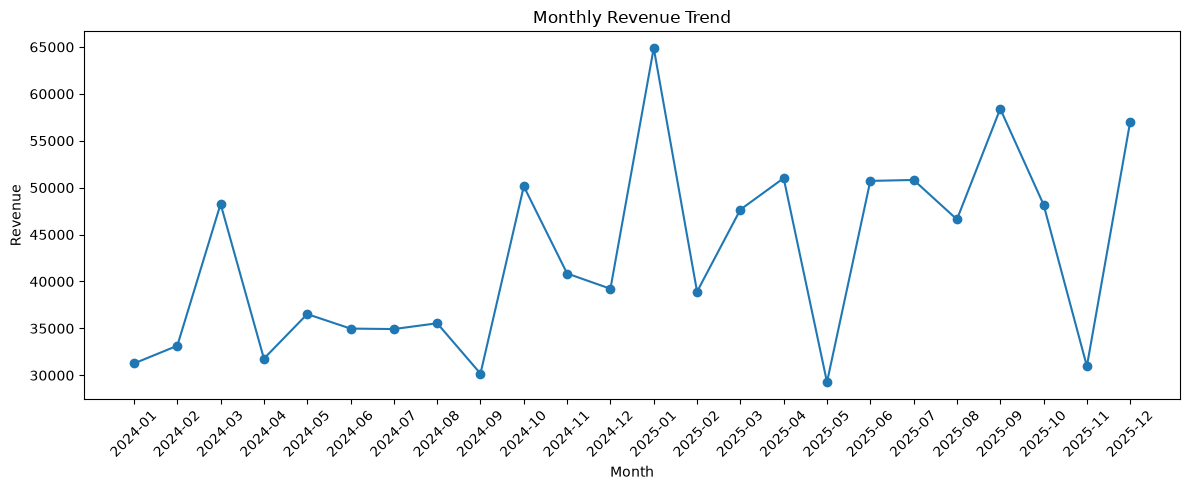

In [17]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Year_Month"].astype(str),monthly_sales["Revenue"],marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
highest_month = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]
lowest_month = monthly_sales.loc[monthly_sales["Revenue"].idxmin()]
print("Highest Sales Month:")
print(highest_month)
print("\nLowest Sales Month:")
print(lowest_month)

Highest Sales Month:
Year_Month     2025-01
Revenue       64883.55
Orders             163
Name: 12, dtype: object

Lowest Sales Month:
Year_Month     2025-05
Revenue       29270.55
Orders             128
Name: 16, dtype: object


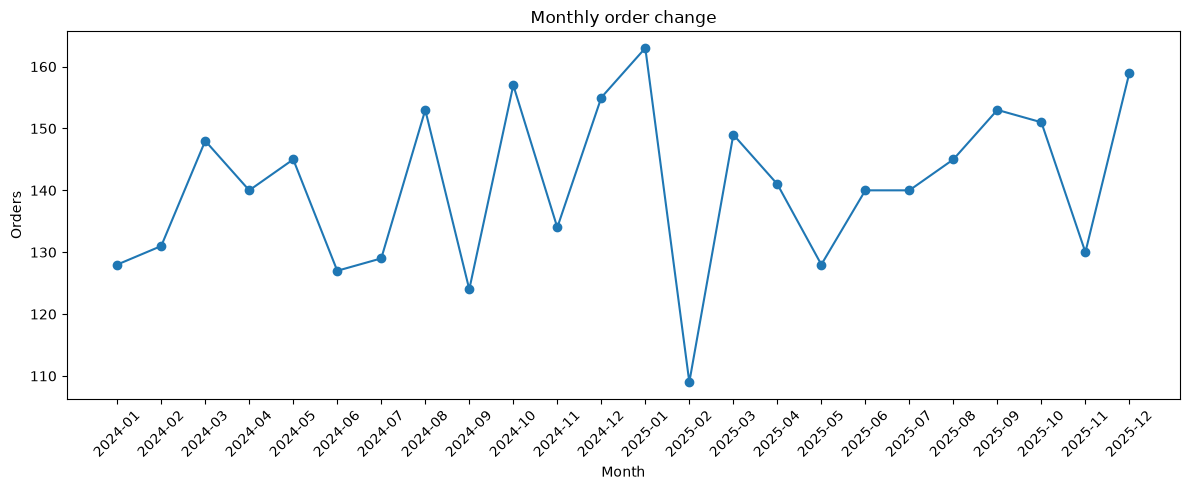

In [20]:
plt.figure(figsize=(12,5))

plt.plot(monthly_sales["Year_Month"].astype(str),monthly_sales["Orders"], marker="o")
plt.title("Monthly order change")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
print(monthly_sales.sort_values("Year_Month"))

   Year_Month   Revenue  Orders
0     2024-01  31260.25     128
1     2024-02  33149.35     131
2     2024-03  48265.10     148
3     2024-04  31774.85     140
4     2024-05  36524.75     145
5     2024-06  34979.15     127
6     2024-07  34928.50     129
7     2024-08  35546.90     153
8     2024-09  30180.65     124
9     2024-10  50144.70     157
10    2024-11  40850.45     134
11    2024-12  39224.70     155
12    2025-01  64883.55     163
13    2025-02  38914.20     109
14    2025-03  47661.45     149
15    2025-04  51014.70     141
16    2025-05  29270.55     128
17    2025-06  50720.15     140
18    2025-07  50822.55     140
19    2025-08  46617.10     145
20    2025-09  58404.85     153
21    2025-10  48197.55     151
22    2025-11  30966.45     130
23    2025-12  57029.15     159


In [24]:
#DAY 23 product and category analysis
product_analysis = df.groupby("Product_Name").agg(
    Revenue=("Sales", "sum"),
    Quantity_Sold=("Quantity", "sum")
).reset_index()

product_analysis = product_analysis.sort_values(
    "Revenue", ascending=False
)
print(product_analysis)

                    Product_Name    Revenue  Quantity_Sold
36                    School Bag  164645.00          269.0
0   A4 Copier Paper - 500 Sheets   72912.00          243.0
3                     Calculator   70412.50          296.0
23                     Lunch Box   54593.00          261.0
32             Poster Colour Set   51552.00          337.0
15                  Fountain Pen   40806.00          237.0
46                  Water Bottle   37827.00          222.0
7                 Desk Organizer   35976.50          201.0
47              Water Colour Set   31446.00          273.0
5           Crayons - Jumbo Pack   29711.50          243.0
17                  Geometry Box   27709.00          266.0
42                       Stapler   25308.00          278.0
40         Sketch Pens - 12 Pack   23910.50          296.0
33         Practical Record Book   23419.00          225.0
29                    Pencil Box   20895.25          231.0
27               Paint Brush Set   19555.75          220

In [25]:
top_products = product_analysis.head(5)
low_products = product_analysis.tail(5)
print("Top 5 Products:")
print(top_products)
print("\nBottom 5 Products:")
print(low_products)

Top 5 Products:
                    Product_Name   Revenue  Quantity_Sold
36                    School Bag  164645.0          269.0
0   A4 Copier Paper - 500 Sheets   72912.0          243.0
3                     Calculator   70412.5          296.0
23                     Lunch Box   54593.0          261.0
32             Poster Colour Set   51552.0          337.0

Bottom 5 Products:
        Product_Name  Revenue  Quantity_Sold
2    Ball Pen - Blue  2693.50          287.0
38         Sharpener  2551.60          340.0
1   Ball Pen - Black  2258.00          239.0
30         Pencil Hb  1089.75          229.0
11            Eraser  1020.25          213.0


In [26]:
category_analysis = df.groupby("Category").agg(
    Revenue=("Sales", "sum"),
    Quantity_Sold=("Quantity", "sum")
).reset_index()

category_analysis = category_analysis.sort_values(
    "Revenue", ascending=False
)

print(category_analysis)

              Category    Revenue  Quantity_Sold
3      School Supplies  342463.35         2297.0
1      Office Supplies  222505.50         3307.0
2       Paper Products  199480.00         2340.0
0          Art & Craft  174741.00         2192.0
4  Writing Instruments   82141.75         2164.0


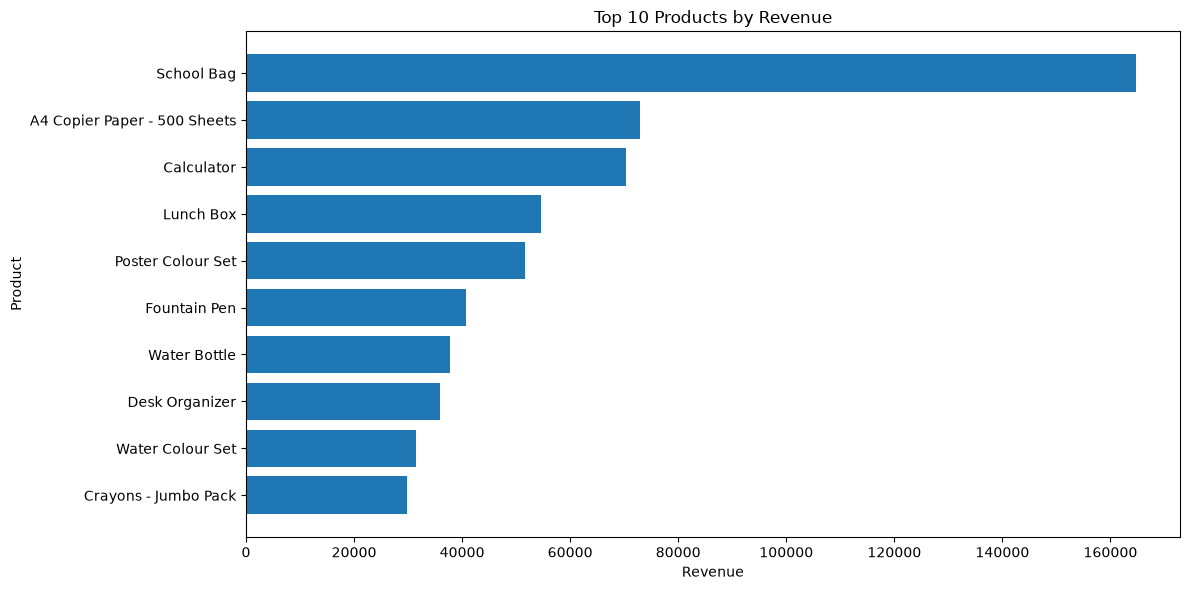

In [27]:
top_10 = product_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(top_10["Product_Name"], top_10["Revenue"])

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

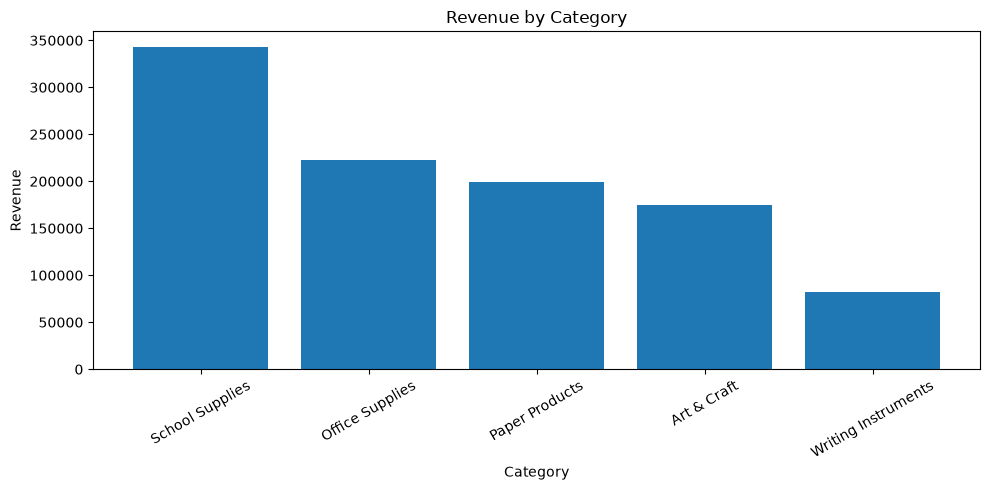

In [28]:
plt.figure(figsize=(10, 5))

plt.bar(category_analysis["Category"], category_analysis["Revenue"])

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [30]:
product_analysis["Revenue_Contribution_Percent"] = (
    product_analysis["Revenue"] / df["Sales"].sum()
) * 100

product_analysis["Quantity_Contribution_Percent"] = (
    product_analysis["Quantity_Sold"] / df["Quantity"].sum()
) * 100

print(product_analysis)

                    Product_Name    Revenue  Quantity_Sold  \
36                    School Bag  164645.00          269.0   
0   A4 Copier Paper - 500 Sheets   72912.00          243.0   
3                     Calculator   70412.50          296.0   
23                     Lunch Box   54593.00          261.0   
32             Poster Colour Set   51552.00          337.0   
15                  Fountain Pen   40806.00          237.0   
46                  Water Bottle   37827.00          222.0   
7                 Desk Organizer   35976.50          201.0   
47              Water Colour Set   31446.00          273.0   
5           Crayons - Jumbo Pack   29711.50          243.0   
17                  Geometry Box   27709.00          266.0   
42                       Stapler   25308.00          278.0   
40         Sketch Pens - 12 Pack   23910.50          296.0   
33         Practical Record Book   23419.00          225.0   
29                    Pencil Box   20895.25          231.0   
27      

In [31]:
#Day 24 Customer performance analysis
customer_analysis = df.groupby("Customer_ID").agg(
    Total_Purchases=("Sales", "sum"),
    Total_Units=("Quantity", "sum"),
    Total_Orders=("Order_ID", "nunique")
).reset_index()

print(customer_analysis.head())

  Customer_ID  Total_Purchases  Total_Units  Total_Orders
0   CUST00001           260.00          4.0             1
1   CUST00002           408.00          7.0             2
2   CUST00003           216.75          3.0             1
3   CUST00004           349.25          6.0             3
4   CUST00005           296.00          5.0             2


In [32]:
customer_analysis["Average_Order_Value"] = (
    customer_analysis["Total_Purchases"] /
    customer_analysis["Total_Orders"]
)

print(customer_analysis.head())

  Customer_ID  Total_Purchases  Total_Units  Total_Orders  Average_Order_Value
0   CUST00001           260.00          4.0             1           260.000000
1   CUST00002           408.00          7.0             2           204.000000
2   CUST00003           216.75          3.0             1           216.750000
3   CUST00004           349.25          6.0             3           116.416667
4   CUST00005           296.00          5.0             2           148.000000


In [33]:
customer_analysis["Customer_Status"] = customer_analysis["Total_Orders"].apply(
    lambda x: "Repeat Customer" if x > 1 else "One-Time Customer"
)

print(customer_analysis["Customer_Status"].value_counts())

Customer_Status
One-Time Customer    1776
Repeat Customer       718
Name: count, dtype: int64


In [34]:
customer_summary = customer_analysis.groupby("Customer_Status").agg(
    Customers=("Customer_ID", "nunique"),
    Revenue=("Total_Purchases", "sum"),
    Orders=("Total_Orders", "sum")
).reset_index()

print(customer_summary)

     Customer_Status  Customers    Revenue  Orders
0  One-Time Customer       1776  548639.45    1776
1    Repeat Customer        718  469861.40    1563


In [13]:
segment_analysis = df.groupby("Customer_Type").agg(
    Revenue=("Sales", "sum"),
    Orders=("Order_ID", "nunique"),
    Units_Sold=("Quantity", "sum"),
    Customers=("Customer_ID", "nunique")
).reset_index()

print(segment_analysis)

     Customer_Type    Revenue  Orders  Units_Sold  Customers
0  Office/Business  217022.45     685      2545.0        649
1  Parent/Guardian  228573.05     754      2708.0        699
2          Student  466665.25    1557      5651.0       1354
3          Teacher   95474.35     315      1225.0        301


In [3]:
#DAY 25 Regional and segment analysis

region_analysis = df.groupby("Region").agg(
    Revenue=("Sales", "sum"),
    Orders=("Order_ID", "nunique"),
    Units_Sold=("Quantity", "sum"),
    Customers=("Customer_ID", "nunique")
).reset_index()

region_analysis = region_analysis.sort_values(
    "Revenue", ascending=False
)

print(region_analysis)

  Region    Revenue  Orders  Units_Sold  Customers
3   West  311610.65     941      3553.0        878
2  South  273766.40     956      3452.0        869
1  North  242693.25     775      2859.0        726
0   East  193261.30     678      2436.0        626


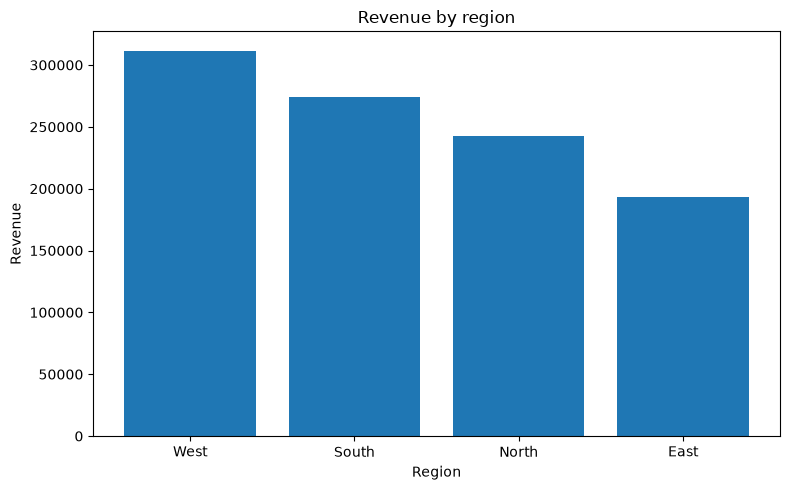

In [7]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(8,5))
plt.bar(region_analysis["Region"],region_analysis["Revenue"])
plt.title("Revenue by region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()


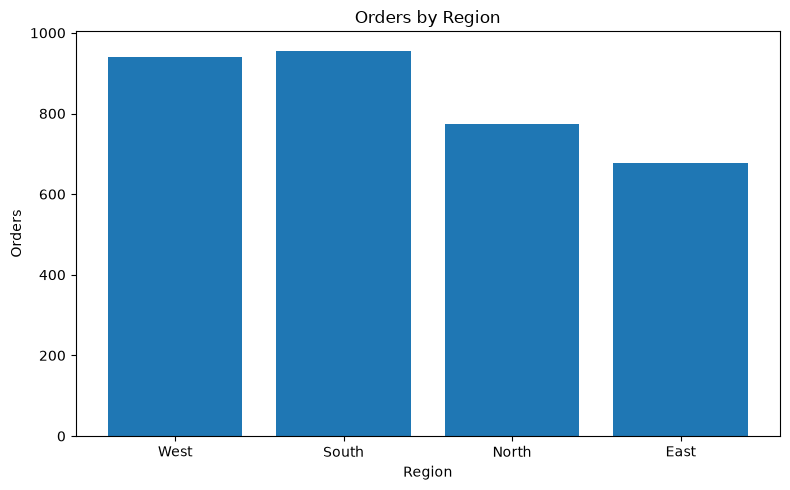

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.bar(region_analysis["Region"],region_analysis["Orders"])
plt.title("Orders by Region")
plt.xlabel("Region")
plt.ylabel("Orders")
plt.tight_layout()
plt.show()

In [2]:
segment_analysis = df.groupby("Customer_Type").agg(
    Revenue=("Sales", "sum"),
    Orders=("Order_ID", "nunique"),
    Units_Sold=("Quantity", "sum"),
    Customers=("Customer_ID", "nunique")
).reset_index()

segment_analysis = segment_analysis.sort_values(
    "Revenue", ascending=False
)

print(segment_analysis)

NameError: name 'df' is not defined

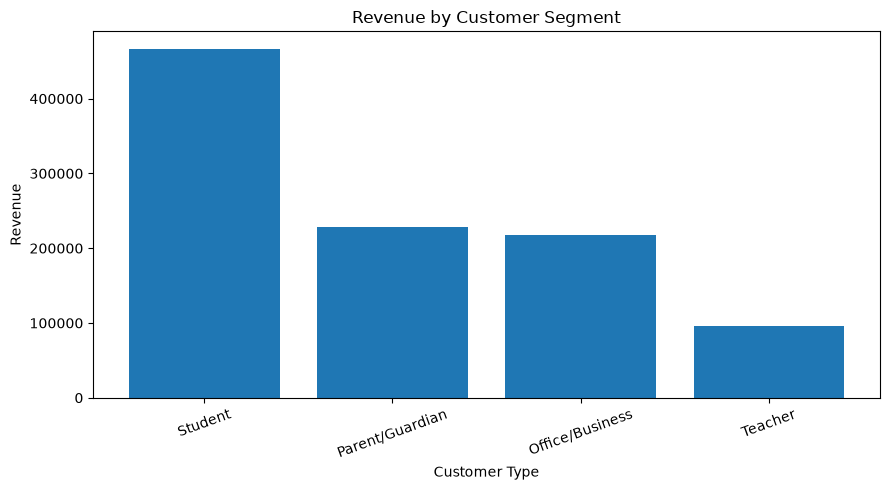

In [15]:
plt.figure(figsize=(9,5))

plt.bar(segment_analysis["Customer_Type"], segment_analysis["Revenue"])

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Type")
plt.ylabel("Revenue")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [16]:
segment_analysis["Average_Order_Value"] = (
    segment_analysis["Revenue"] / segment_analysis["Orders"]
)

print(
    segment_analysis[
        ["Customer_Type", "Revenue", "Orders", "Units_Sold",
         "Customers", "Average_Order_Value"]
    ].sort_values("Revenue", ascending=False)
)

     Customer_Type    Revenue  Orders  Units_Sold  Customers  \
2          Student  466665.25    1557      5651.0       1354   
1  Parent/Guardian  228573.05     754      2708.0        699   
0  Office/Business  217022.45     685      2545.0        649   
3          Teacher   95474.35     315      1225.0        301   

   Average_Order_Value  
2           299.720777  
1           303.147281  
0           316.821095  
3           303.093175  


In [1]:
segment_product_analysis = df.groupby(
    ["Customer_Type", "Product_Name"]
).agg(
    Revenue=("Sales", "sum"),
    Quantity_Sold=("Quantity", "sum")
).reset_index()

NameError: name 'df' is not defined

In [18]:
top_segment_products = segment_product_analysis.sort_values(
    ["Customer_Type", "Revenue"],
    ascending=[True, False]
).groupby("Customer_Type").head(5)

print(top_segment_products)

       Customer_Type                  Product_Name  Revenue  Quantity_Sold
36   Office/Business                    School Bag  38480.0           63.0
23   Office/Business                     Lunch Box  14993.0           72.0
0    Office/Business  A4 Copier Paper - 500 Sheets  13392.0           44.0
46   Office/Business                  Water Bottle  13131.0           77.0
3    Office/Business                    Calculator  11812.5           50.0
85   Parent/Guardian                    School Bag  38967.5           63.0
49   Parent/Guardian  A4 Copier Paper - 500 Sheets  13488.0           44.0
64   Parent/Guardian                  Fountain Pen  13338.0           78.0
52   Parent/Guardian                    Calculator  13000.0           55.0
96   Parent/Guardian              Water Colour Set  12582.0          108.0
134          Student                    School Bag  77577.5          127.0
101          Student                    Calculator  40925.0          171.0
98           Student  A4 